In [2]:
import sklearn.datasets as skdata
from datetime import datetime as dt

start = dt.now()
newsgroups = skdata.fetch_20newsgroups_vectorized()
end = dt.now()
print(f"It took {end - start} to download and vectorize the newsgroups data")  # took a couple minutes the first time this was run...

# features (X) derived  from word frequencies, targets (y) are topics we'll try to predict
X, y = newsgroups.data, newsgroups.target
X.shape, y.shape

It took 0:00:00.493977 to download and vectorize the newsgroups data


((11314, 130107), (11314,))

In [6]:
from sklearn.neighbors import KNeighborsClassifier

# create and fit a KNN model on entire dataset
knn = KNeighborsClassifier(n_neighbors=1)
knn.fit(X, y)  # standard syntax across sklearn
y_pred = knn.predict(X)  # predict on each training instance
knn.score(X, y)  # not very useful because this is on data the model has seen

0.9999116139296447

## High accuracy on the training data

This isn't very useful, because this is what the model was trained on. What we want is to understand how the model generalizes to **unseen** data. To do this, we typically partition the data into **training** and **testing** sets.

In [9]:
from sklearn.model_selection import train_test_split

# default split: 75% train, 25% test
X_train, X_test, y_train, y_test = train_test_split(X, y)
knn.fit(X_train, y_train)
knn.score(X_test, y_test)  # expect this to be lower

0.6733828207847296

## Different models from different splits

If we do a bunch of different splits on the data, we'll get a slightly different model each time because they will see different data.

(array([ 4., 13., 19., 14., 17., 16., 10.,  4.,  2.,  1.]),
 array([0.65288088, 0.65726405, 0.66164723, 0.6660304 , 0.67041357,
        0.67479675, 0.67917992, 0.6835631 , 0.68794627, 0.69232945,
        0.69671262]),
 <BarContainer object of 10 artists>)

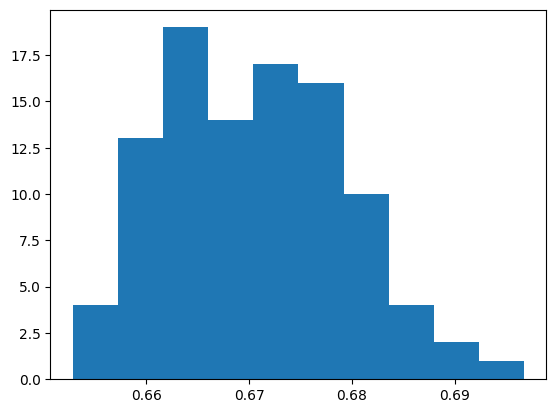

In [11]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

knn_scores = []
for i in range(100):
    X_train, X_test, y_train, y_test = train_test_split(X, y)
    knn.fit(X_train, y_train)
    knn_score = knn.score(X_test, y_test)
    knn_scores.append(knn_score)

plt.hist(np.array(knn_scores))

## Comparing KNN models

Choice of hyperparameters can have a noticeable impact on performance.

In [21]:
# import the UCI digit images
# https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html#sklearn.datasets.load_digits
start = dt.now()
X_digits, y_digits = skdata.load_digits(return_X_y=True)  # (numpy.ndarray, numpy.ndarray)
end = dt.now()

print(X_digits.shape, y_digits.shape)  # features, targets
y_digits[:20]

(1797, 64) (1797,)


array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9])